In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ast import literal_eval
pd.set_option('display.max_columns', None)


In [23]:
df = pd.read_csv("D:\\Projects\\PFA\\gps-digital-twin\\data\\raw\\train.csv")
print(df.shape)
print(df.head())
df.dtypes

(1710670, 9)
               TRIP_ID CALL_TYPE  ORIGIN_CALL  ORIGIN_STAND   TAXI_ID  \
0  1372636858620000589         C          NaN           NaN  20000589   
1  1372637303620000596         B          NaN           7.0  20000596   
2  1372636951620000320         C          NaN           NaN  20000320   
3  1372636854620000520         C          NaN           NaN  20000520   
4  1372637091620000337         C          NaN           NaN  20000337   

    TIMESTAMP DAY_TYPE  MISSING_DATA  \
0  1372636858        A         False   
1  1372637303        A         False   
2  1372636951        A         False   
3  1372636854        A         False   
4  1372637091        A         False   

                                            POLYLINE  
0  [[-8.618643,41.141412],[-8.618499,41.141376],[...  
1  [[-8.639847,41.159826],[-8.640351,41.159871],[...  
2  [[-8.612964,41.140359],[-8.613378,41.14035],[-...  
3  [[-8.574678,41.151951],[-8.574705,41.151942],[...  
4  [[-8.645994,41.18049],[-8.645

TRIP_ID           int64
CALL_TYPE        object
ORIGIN_CALL     float64
ORIGIN_STAND    float64
TAXI_ID           int64
TIMESTAMP         int64
DAY_TYPE         object
MISSING_DATA       bool
POLYLINE         object
dtype: object

In [15]:
print(df.isnull().sum())
df["MISSING_DATA"].value_counts()

TRIP_ID               0
CALL_TYPE             0
ORIGIN_CALL     1345900
ORIGIN_STAND     904091
TAXI_ID               0
TIMESTAMP             0
DAY_TYPE              0
MISSING_DATA          0
POLYLINE              0
dtype: int64


MISSING_DATA
False    1710660
True          10
Name: count, dtype: int64

In [21]:
sample = df["POLYLINE"].iloc[0]
print(sample)
print(type(sample))

parsed = literal_eval(sample)
print(parsed[:3])
print(type(parsed))
print(len(parsed))


[[-8.618643,41.141412],[-8.618499,41.141376],[-8.620326,41.14251],[-8.622153,41.143815],[-8.623953,41.144373],[-8.62668,41.144778],[-8.627373,41.144697],[-8.630226,41.14521],[-8.632746,41.14692],[-8.631738,41.148225],[-8.629938,41.150385],[-8.62911,41.151213],[-8.629128,41.15124],[-8.628786,41.152203],[-8.628687,41.152374],[-8.628759,41.152518],[-8.630838,41.15268],[-8.632323,41.153022],[-8.631144,41.154489],[-8.630829,41.154507],[-8.630829,41.154516],[-8.630829,41.154498],[-8.630838,41.154489]]
<class 'str'>
[[-8.618643, 41.141412], [-8.618499, 41.141376], [-8.620326, 41.14251]]
<class 'list'>
23


In [24]:
df["n_points"] = df["POLYLINE"].apply(lambda s: len(literal_eval(s)) if pd.notna(s) else 0)
df["duration_min"] = (df["n_points"] - 1).clip(lower=0) * 15 / 60

In [30]:
df["n_points"].describe()

count    1.710670e+06
mean     4.875831e+01
std      4.565372e+01
min      0.000000e+00
25%      2.800000e+01
50%      4.100000e+01
75%      5.900000e+01
max      3.881000e+03
Name: n_points, dtype: float64

In [29]:
df["duration_min"].describe()

count    1.710670e+06
mean     1.194044e+01
std      1.141252e+01
min      0.000000e+00
25%      6.750000e+00
50%      1.000000e+01
75%      1.450000e+01
max      9.700000e+02
Name: duration_min, dtype: float64

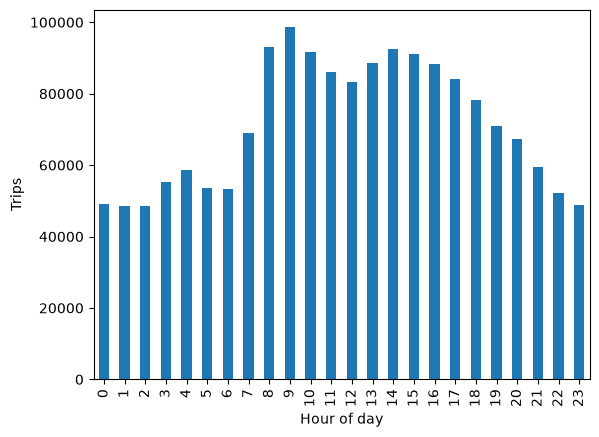

In [32]:
df["hour"] = df["start_dt"].dt.hour
df["hour"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Hour of day")
plt.ylabel("Trips")
plt.show()

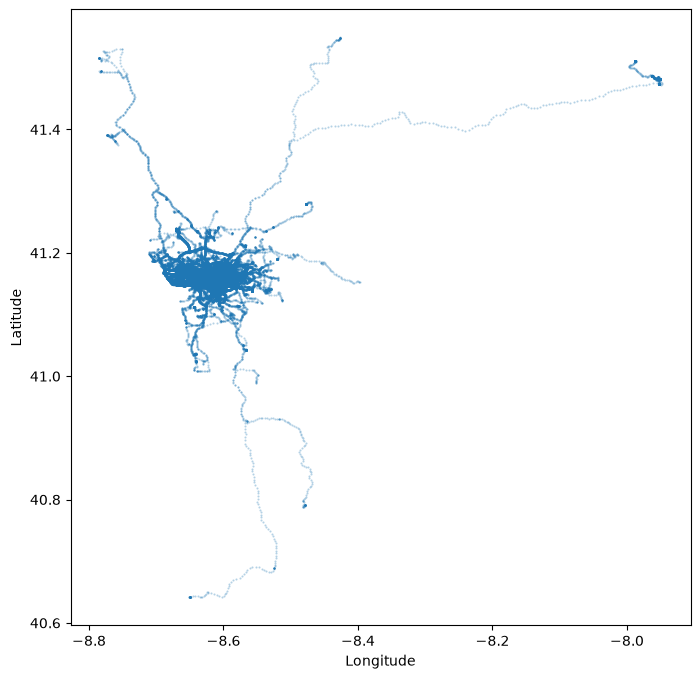

In [33]:
# take a sample of trips so this doesn't take forever
sample_df = df.sample(2000, random_state=42)

all_points = []
for poly in sample_df["POLYLINE"]:
    pts = literal_eval(poly)
    all_points.extend(pts)

all_points = np.array(all_points)
plt.figure(figsize=(8,8))
plt.scatter(all_points[:,0], all_points[:,1], s=0.3, alpha=0.3)
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()